## Финальный проект

#### *«Я чувствую себя как функция арктангенса, которая приближается к асимптоте.» — Теория большого взрыва*

Это финальный проект продуктового блока курса «Продуктовые метрики». За него можно получить максимум 60 баллов.

**Дедлайны**   
Жесткий дедлайн: 25.10.2026 23:59 по МСК.

После жесткого дедлайна работы не принимаются.

**Правила сдачи**   
Задание выполняется самостоятельно, списывания не допускаются. При обнаружении одинаковых работ балл за задание аннулируется у всех студентов, вне зависимости от того, кто у кого списал.    

**Использование ИИ**
- Использование генеративных моделей для написания кода допустимо при следующих условиях: сгенерированный фрагмент прочитан, адаптирован под условие задачи и данные, вы способны объяснить каждую его строку. Решение, полученное путем передачи модели формулировки задания целиком и прямого копирования ответа в ячейку ноутбука без содержательной переработки, оценивается в 0 баллов за это задание.
- Ответы на текстовые вопросы (описание поведения графика, интерпретация метрики, формулировка гипотез и т.п.) должны быть написаны вами самостоятельно в markdown-ячейках. Использование генеративных моделей для ответа на текстовые вопросы приводит к аннулированию всей работы, а не отдельного задания: интерпретация результатов — главный проверяемый в курсе навык, передача ее ИИ лишает нас возможности оценить, насколько хорошо вы усвоили материал.
- Если генеративная модель использовалась при решении, в конце ноутбука в отдельной markdown-ячейке укажите: номера заданий, при работе над которыми она применялась, использованную модель (с версией) и текст промтов. При обоснованном подозрении на использование ИИ, не отраженное в этом разделе, работа аннулируется целиком независимо от того, к какой части заданий относится подозрение.

#### **Как сдать домашку?**
1. Создайте закрытый репозиторий в личном гитхаб аккаунте для нашего предмета.
2. Пригласите в него своего ассистента — распределение по ассистентам и их гитхаб юзернеймы находятся в ведомости на листочке нашей дисциплины. Это можно сделать в настройках через раздел Collaborators and teams, уровень доступа ассистента должен быть Write.
3. Скачайте этот ноутбук и решите задания (локально или в Google Colab).
4. В репозитории предмета создайте ветку с номером ДЗ (например final_project). В эту ветку запушьте .ipynb-файл с решением. Создайте pull request и добавьте в него ассистента как Reviewer. В этот же PR можете пушить сколько угодно изменений, будем смотреть на последнюю версию до наступления дедлайна.
5. Ссылку на PR продублируйте в форме сдачи (форма будет доступна на LMS Karpov Courses и в Телеграм-канале курса).

Пункты 1-2 проделываются один раз. Если вы прошли эти шаги при сдаче других домашек, повторять их не нужно, начинайте сразу с пункта 3.

**Внимание**: Если вы работаете в Google Colab, также скачивайте .ipynb файл и публикуйте его в репозитории. Ссылки на Colab к сдаче не принимаются.


Все датасеты, с которыми предлагается работать в домашних заданиях, взяты из открытых источников или сгенерированы. Любые паттерны, найденные вне заданной канвы решения, являются случайными и не несут в себе смысла или инсайта.

[Данные](https://github.com/brezhnevaan/hse_product_metrics_course/releases/download/datasets_for_hw/final_project_data.zip)

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import requests

from statsmodels.tsa.seasonal import STL
from scipy.stats import norm
from scipy.stats import t
import math

import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

### Case Study. Улучшение сервиса доставки из ресторанов 🌮

**Легенда**   
Вы присоединились к продуктовой команде сервиса доставки из ресторанов в роли аналитика. Близится планирование следующего квартала, пора готовить бэклог инициатив. Продакт-менеджер особенно беспокоится об удовлетворенности пользователей — за последний месяц выросло число отмен и жалоб на задержки.

Вам поставлена задача: провести исследование текущих значений метрик, выдвинуть гипотезу о проблеме и предложить её решение.

In [6]:
df = pd.read_csv('final_project_delivery.csv', parse_dates=["order_time", "delivery_time"])

df.head()

,order_id,order_time,delivery_time,status,cancellation_reason,order_value,delivery_fee,estimated_delivery_time_min,time_to_assign_courier_min,actual_preparation_time_min,travel_time_min,delivery_distance_km,promotion_used,platform,city_region,user_id,user_segment
0,257,2022-11-01 00:01:46,2022-11-01 00:21:52,delivered,NaN,25.73,2.09,27.0,10.2,15.1,5.0,3.48,no,Android,Belem,5737,returning
1,165,2022-11-01 00:06:07,2022-11-01 00:27:01,delivered,NaN,22.00,0.77,13.0,9.0,15.9,5.0,1.29,no,iOS,Parque das Nacoes,4095,new
2,343,2022-11-01 21:07:01,2022-11-01 21:40:07,delivered,NaN,29.90,3.53,44.0,10.6,15.4,15.1,5.88,no,iOS,Parque das Nacoes,15991,returning
3,904,2022-11-01 00:06:48,2022-11-01 00:36:42,delivered,NaN,40.49,2.02,27.0,3.7,16.0,13.9,3.36,no,Android,Alfama,1773,returning
4,555,2022-11-01 00:09:58,2022-11-01 00:57:22,delivered,NaN,35.75,3.48,39.0,5.2,12.3,35.1,5.80,no,iOS,Baixa,5203,returning


Описание данных:

- order_id — уникальный идентификатор заказа
- order_time — timestamp создания заказа
- delivery_time – timestamp доставки заказа
- status — статус заказа, принимает 2 значения: delivered и cancelled
- cancellation_reason — причина отмены заказа: Cancelled by user (отменена пользователем) и No courier available (нет доступных курьеров)
- order_value — стоимость заказа
- delivery_fee — стоимость доставки
- estimated_delivery_time_min — прогнозное время доставки
- time_to_assign_courier_min — время до назначения курьера
- actual_preparation_time_min — время приготовления заказа рестораном
- travel_time_min — суммарное время на дорогу курьера до ресторана и до конечного пользователя
- delivery_distance_km — расстояние от адреса доставки до адреса ресторана
- promotion_used — был ли заказ совершен с использованием промокода или акции
- platform — платформа, с которой совершен заказ
- city_region — район города, в который планируется доставка
- user_id — уникальный идентификатор пользователя, сделавшего заказ
- user_segment — сегмент пользователя (новый или вернувшийся)    

### Часть 1. Исследование

#### 1. Динамика основных метрик — 3 балла
Рассчитайте и визуализируйте по дням:
- Число заказов, число доставленных заказов (статус delivered);
- Completion Rate (Доставленные заказы / Все заказы), Cancellation Rate (Отмененные заказы / Все заказы);
- Среднее и медианное время доставки в минутах (рассчитывается как разница между delivery_time и order_time), средний чек заказа, среднюю стоимость доставки.

Сделайте выводы:
- Есть ли выраженный тренд?
- Может быть какие-то дни кажутся подозрительными на предмет аномалий?

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df["order_date"] = df["order_time"].dt.date

df["delivery_min"] = (df["delivery_time"] - df["order_time"]).dt.total_seconds() / 60

daily = df.groupby("order_date").agg(
    orders_total      = ("order_id", "count"),
    orders_delivered  = ("status", lambda s: (s == "delivered").sum()),
    orders_cancelled  = ("status", lambda s: (s == "cancelled").sum()),
    avg_delivery_min  = ("delivery_min", "mean"),
    median_delivery_min = ("delivery_min", "median"),
    avg_order_value   = ("order_value", "mean"),
    avg_delivery_fee  = ("delivery_fee", "mean"),
).reset_index()

daily["completion_rate"]   = daily["orders_delivered"] / daily["orders_total"]
daily["cancellation_rate"] = daily["orders_cancelled"] / daily["orders_total"]

assert np.allclose(daily["completion_rate"] + daily["cancellation_rate"], 1)

print(daily.round(3).to_string(index=False))

order_date  orders_total  orders_delivered  orders_cancelled  avg_delivery_min  median_delivery_min  avg_order_value  avg_delivery_fee  completion_rate  cancellation_rate
2022-11-01          1009               963                46            31.517                30.10           25.092             2.285            0.954              0.046
2022-11-02           993               952                41            31.726                29.60           25.405             2.391            0.959              0.041
2022-11-03           992               925                67            34.354                32.70           25.205             2.375            0.932              0.068
2022-11-04          1535              1463                72            31.756                30.00           25.361             2.384            0.953              0.047
2022-11-05          1514              1446                68            30.829                28.70           24.674             2.358           

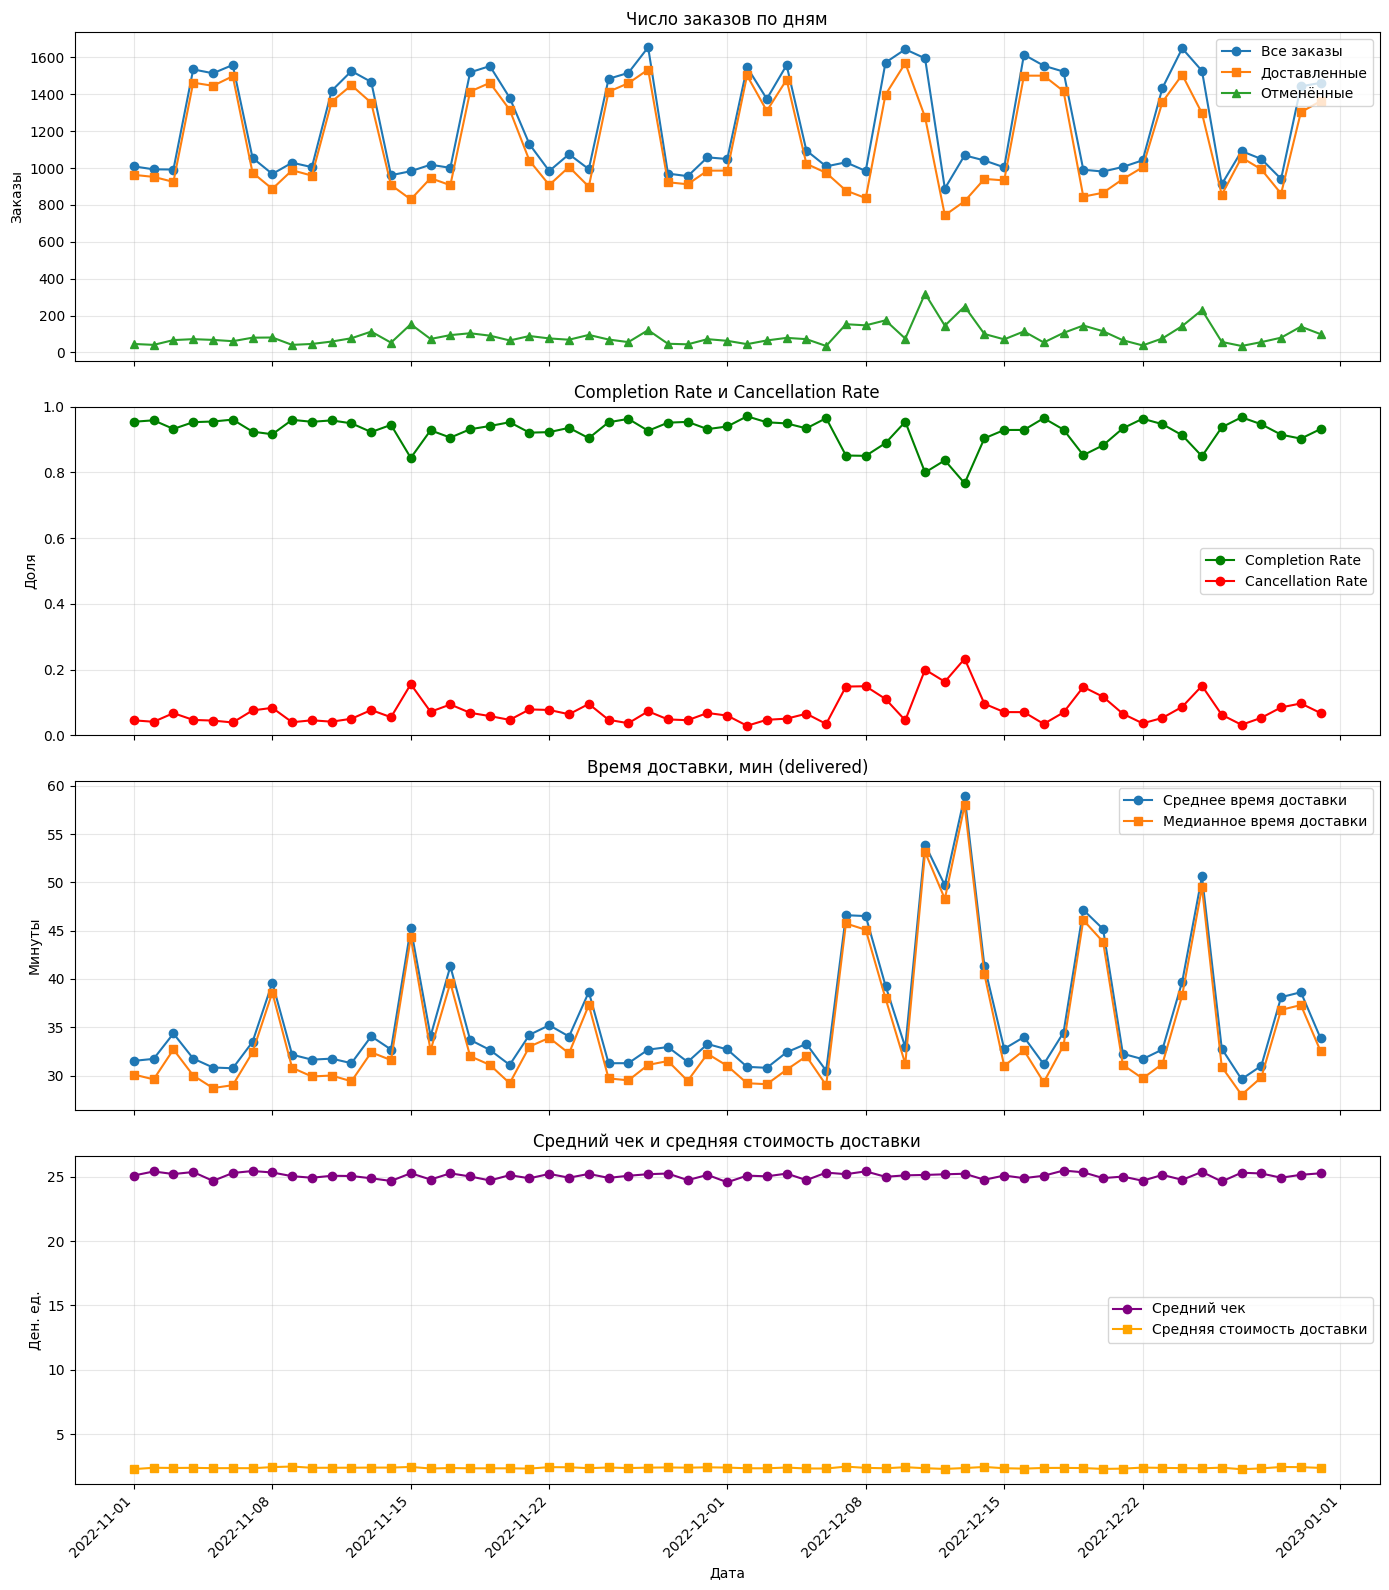

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

ax = axes[0]
ax.plot(daily["order_date"], daily["orders_total"],     marker="o", label="Все заказы")
ax.plot(daily["order_date"], daily["orders_delivered"], marker="s", label="Доставленные")
ax.plot(daily["order_date"], daily["orders_cancelled"], marker="^", label="Отменённые")
ax.set_title("Число заказов по дням")
ax.set_ylabel("Заказы")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(daily["order_date"], daily["completion_rate"],   marker="o", color="green", label="Completion Rate")
ax.plot(daily["order_date"], daily["cancellation_rate"], marker="o", color="red",   label="Cancellation Rate")
ax.set_title("Completion Rate и Cancellation Rate")
ax.set_ylabel("Доля")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

ax = axes[2]
ax.plot(daily["order_date"], daily["avg_delivery_min"],    marker="o", label="Среднее время доставки")
ax.plot(daily["order_date"], daily["median_delivery_min"], marker="s", label="Медианное время доставки")
ax.set_title("Время доставки, мин (delivered)")
ax.set_ylabel("Минуты")
ax.legend()
ax.grid(alpha=0.3)

ax = axes[3]
ax.plot(daily["order_date"], daily["avg_order_value"],  marker="o", color="purple", label="Средний чек")
ax.plot(daily["order_date"], daily["avg_delivery_fee"], marker="s", color="orange", label="Средняя стоимость доставки")
ax.set_title("Средний чек и средняя стоимость доставки")
ax.set_ylabel("Ден. ед.")
ax.set_xlabel("Дата")
ax.legend()
ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [13]:
from scipy import stats

x = np.arange(len(daily))
for col in ["orders_total", "completion_rate", "cancellation_rate",
            "avg_delivery_min", "avg_order_value", "avg_delivery_fee"]:
    slope, intercept, r, p, se = stats.linregress(x, daily[col])
    trend = "рост" if slope > 0 else "падение"
    sig   = "значим" if p < 0.05 else "не значим"
    print(f"{col:25s}: slope={slope:+.4f}/день, p={p:.3f} → тренд {trend} ({sig})")

print("\nПодозрительные дни (|z| > 2):")
for col in ["orders_total", "completion_rate", "cancellation_rate", "avg_delivery_min"]:
    z = (daily[col] - daily[col].mean()) / daily[col].std(ddof=0)
    outliers = daily.loc[z.abs() > 2, ["order_date", col]]
    if not outliers.empty:
        print(f"\n[{col}]")
        print(outliers.to_string(index=False))

orders_total             : slope=+0.7832/день, p=0.686 → тренд рост (не значим)
completion_rate          : slope=-0.0006/день, p=0.038 → тренд падение (значим)
cancellation_rate        : slope=+0.0006/день, p=0.038 → тренд рост (значим)
avg_delivery_min         : slope=+0.1044/день, p=0.026 → тренд рост (значим)
avg_order_value          : slope=-0.0004/день, p=0.803 → тренд падение (не значим)
avg_delivery_fee         : slope=-0.0003/день, p=0.410 → тренд падение (не значим)

Подозрительные дни (|z| > 2):

[completion_rate]
order_date  completion_rate
2022-12-11         0.800000
2022-12-12         0.836895
2022-12-13         0.767072

[cancellation_rate]
order_date  cancellation_rate
2022-12-11           0.200000
2022-12-12           0.163105
2022-12-13           0.232928

[avg_delivery_min]
order_date  avg_delivery_min
2022-12-11         53.922492
2022-12-12         49.716398
2022-12-13         58.949268
2022-12-25         50.635929


Completion Rate значимо падает, Cancellation Rate значимо растёт

Среднее время доставки значимо растёт (+0.1 мин/день  +3 мин за месяц). За тот же период чек и стоимость доставки не меняются → проблема не в спросе и не в тарифах, а в операционке (курьеры / рестораны / логистика)

Поскольку orders_total не растёт, нагрузка не объясняет замедление — скорее всего, ухудшается доступность курьеров или растёт время приготовления/дороги.

#### 2. Выявление аномалий — 3 балла
Проверьте построенные дневные ряды следующих метрик на аномальность:
- Число заказов, число доставленных заказов;
- Completion Rate, Cancellation Rate;
- Время доставки (среднее и медиана).

Для метрик, в которых визуально заметна недельная сезонность (абсолютные метрики), используйте STL-разложение + 3σ, для других — просто 3σ (вы проводите ретроспективный анализ, а не имитируете онлайн-проверку, не забывайте об этом в реализации).

Дайте короткий комментарий по результатам проверки.

In [15]:
daily = df.groupby("order_date").agg(
    orders_total     = ("order_id", "count"),
    orders_delivered = ("status", lambda s: (s == "delivered").sum()),
    orders_cancelled = ("status", lambda s: (s == "cancelled").sum()),
    avg_delivery_min = ("delivery_min", "mean"),
    median_delivery_min = ("delivery_min", "median"),
    avg_order_value  = ("order_value", "mean"),
    avg_delivery_fee = ("delivery_fee", "mean"),
).reset_index()

daily["completion_rate"]   = daily["orders_delivered"] / daily["orders_total"]
daily["cancellation_rate"] = daily["orders_cancelled"] / daily["orders_total"]
daily["order_date"] = pd.to_datetime(daily["order_date"])
daily = daily.sort_values("order_date").set_index("order_date").asfreq("D")

In [17]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

In [18]:
ABS_METRICS = ["orders_total", "orders_delivered", "orders_cancelled"]

def stl_anomalies(series: pd.Series, period: int = 7, k: float = 3.0):
    s = series.dropna().asfreq("D")

    if len(s) < 2 * period:
        return pd.Series(False, index=s.index), None
    res = STL(s, period=period, robust=True).fit()
    resid = res.resid.dropna()
    mu, sd = resid.mean(), resid.std(ddof=0)   # ретроспективно: по всему ряду
    flags = (resid - mu).abs() > k * sd
    return flags.reindex(s.index, fill_value=False), res

anomalies_abs = {}
for col in ABS_METRICS:
    flags, res = stl_anomalies(daily[col])
    anomalies_abs[col] = flags
    print(f"\n[{col}] аномальные дни (STL + 3σ на остатках):")
    print(daily.loc[flags, [col]].to_string())


[orders_total] аномальные дни (STL + 3σ на остатках):
            orders_total
order_date              
2022-12-03          1375

[orders_delivered] аномальные дни (STL + 3σ на остатках):
            orders_delivered
order_date                  
2022-12-03              1310
2022-12-27              1057

[orders_cancelled] аномальные дни (STL + 3σ на остатках):
            orders_cancelled
order_date                  
2022-12-11               319
2022-12-13               249


In [20]:
REL_METRICS = ["completion_rate", "cancellation_rate",
               "avg_delivery_min", "median_delivery_min",
               "avg_order_value", "avg_delivery_fee"]

anomalies_rel = {}
for col in REL_METRICS:
    s = daily[col].dropna()
    mu, sd = s.mean(), s.std(ddof=0)
    flags = (s - mu).abs() > 3 * sd
    anomalies_rel[col] = flags.reindex(daily.index, fill_value=False)
    print(f"\n[{col}] аномальные дни (3σ):")
    print(daily.loc[anomalies_rel[col], [col]].to_string())


[completion_rate] аномальные дни (3σ):
            completion_rate
order_date                 
2022-12-13         0.767072

[cancellation_rate] аномальные дни (3σ):
            cancellation_rate
order_date                   
2022-12-13           0.232928

[avg_delivery_min] аномальные дни (3σ):
            avg_delivery_min
order_date                  
2022-12-13         58.949268

[median_delivery_min] аномальные дни (3σ):
            median_delivery_min
order_date                     
2022-12-13                 58.0

[avg_order_value] аномальные дни (3σ):
Empty DataFrame
Columns: [avg_order_value]
Index: []

[avg_delivery_fee] аномальные дни (3σ):
Empty DataFrame
Columns: [avg_delivery_fee]
Index: []


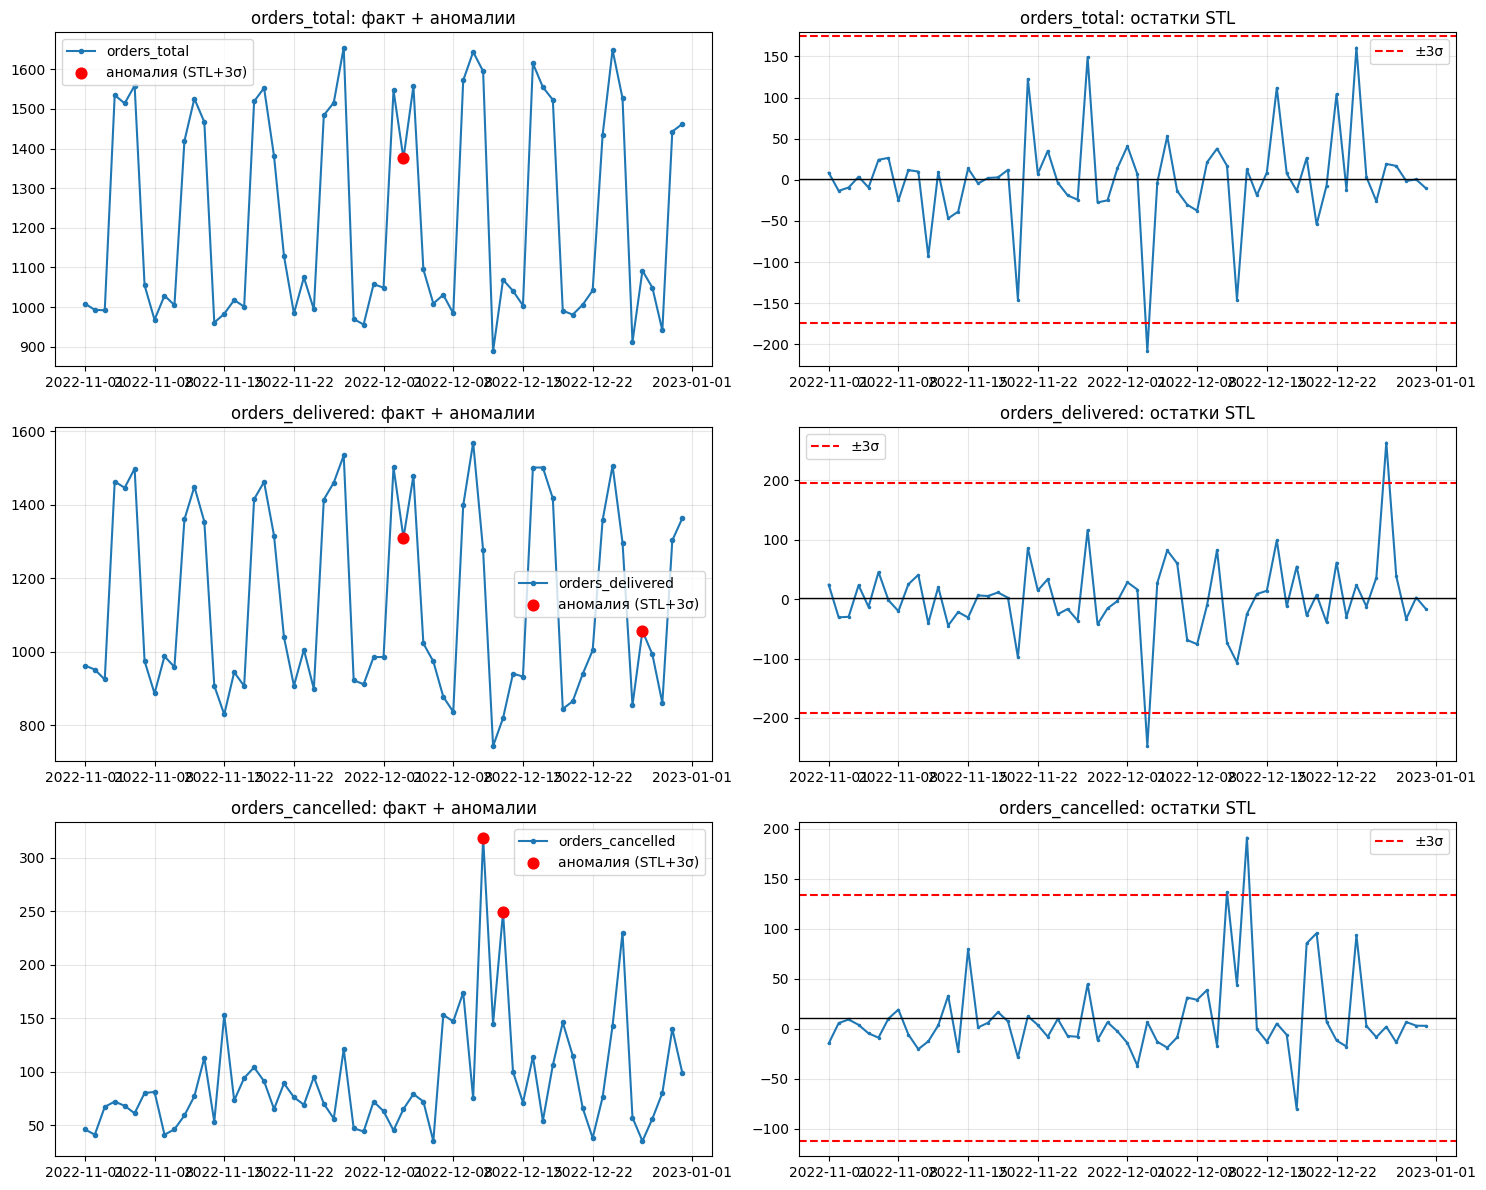

In [21]:
fig, axes = plt.subplots(len(ABS_METRICS), 2, figsize=(15, 4 * len(ABS_METRICS)))
for i, col in enumerate(ABS_METRICS):
    flags, res = stl_anomalies(daily[col])

    ax = axes[i, 0]
    ax.plot(daily.index, daily[col], marker="o", ms=3, label=col)
    ax.scatter(daily.index[flags], daily.loc[flags, col], color="red", zorder=5,
               s=60, label="аномалия (STL+3σ)")
    ax.set_title(f"{col}: факт + аномалии")
    ax.legend(); ax.grid(alpha=0.3)

    ax = axes[i, 1]
    resid = res.resid
    mu, sd = resid.mean(), resid.std(ddof=0)
    ax.plot(daily.index, resid, marker=".", ms=3)
    ax.axhline(mu, color="k", lw=1)
    ax.axhline(mu + 3 * sd, color="r", ls="--", label="±3σ")
    ax.axhline(mu - 3 * sd, color="r", ls="--")
    ax.set_title(f"{col}: остатки STL")
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

#### 3. Поиск причин аномального поведения (шаг 1) — 3 балла
Разложим метрики, в которых обнаружены аномалии, на составляющие.

Визуализируйте:
- Отмены в разрезе причин (абсолютная метрика);
- Длительность этапов, из которых складывается итоговая продолжительность доставки (time_to_assign_courier_min, actual_preparation_time_min, travel_time_min). Берите среднее или медиану на ваш выбор.

Есть ли какие-нибудь закономерности?

In [23]:
daily_idx = pd.date_range(df["order_date"].min(), df["order_date"].max(), freq="D")
canc = (df[df["status"] == "cancelled"]
        .assign(order_date=lambda d: pd.to_datetime(d["order_date"]))
        .groupby(["order_date", "cancellation_reason"])
        .size().unstack(fill_value=0)
        .reindex(daily_idx, fill_value=0))


deliv = df[df["status"] == "delivered"].copy()
deliv["order_date"] = pd.to_datetime(deliv["order_date"])
stages = ["time_to_assign_courier_min", "actual_preparation_time_min", "travel_time_min"]

stage_mean = deliv.groupby("order_date")[stages].mean().reindex(daily_idx)
stage_med  = deliv.groupby("order_date")[stages].median().reindex(daily_idx)


ANOM_A = pd.to_datetime(["2022-12-11", "2022-12-12", "2022-12-13"])
ANOM_B = pd.to_datetime(["2022-12-25"])

def highlight(ax, dates, color, label):
    for d in dates:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12),
                   color=color, alpha=0.15, label=label)

In [24]:
deliv = df[df["status"] == "delivered"].copy()
deliv["order_date"] = pd.to_datetime(deliv["order_date"])
stages = ["time_to_assign_courier_min", "actual_preparation_time_min", "travel_time_min"]

stage_mean = deliv.groupby("order_date")[stages].mean().reindex(daily_idx)
stage_med  = deliv.groupby("order_date")[stages].median().reindex(daily_idx)


ANOM_A = pd.to_datetime(["2022-12-11", "2022-12-12", "2022-12-13"])
ANOM_B = pd.to_datetime(["2022-12-25"])

def highlight(ax, dates, color, label):
    for d in dates:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12),
                   color=color, alpha=0.15, label=label)

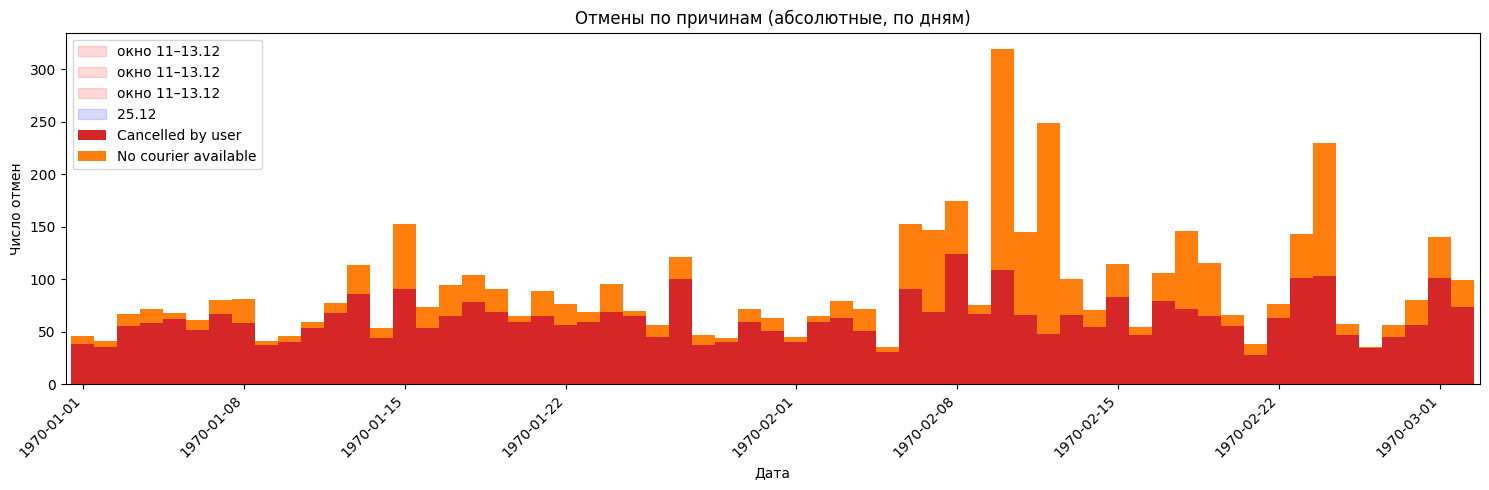

In [25]:
fig, ax = plt.subplots(figsize=(15, 5))
canc.plot(kind="bar", stacked=True, ax=ax, width=1.0,
          color=["#d62728", "#ff7f0e"])
ax.set_title("Отмены по причинам (абсолютные, по дням)")
ax.set_ylabel("Число отмен")
ax.set_xlabel("Дата")
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
highlight(ax, ANOM_A, "red",  "окно 11–13.12")
highlight(ax, ANOM_B, "blue", "25.12")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

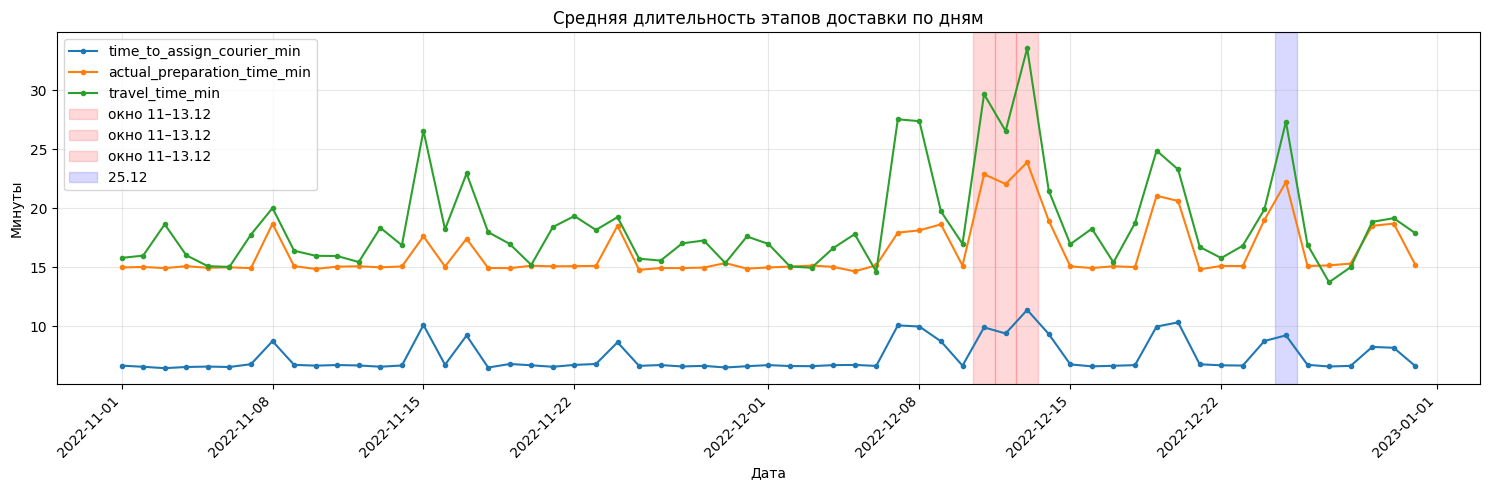

In [26]:
fig, ax = plt.subplots(figsize=(15, 5))
for col in stages:
    ax.plot(stage_mean.index, stage_mean[col], marker="o", ms=3, label=col)
ax.set_title("Средняя длительность этапов доставки по дням")
ax.set_ylabel("Минуты")
ax.set_xlabel("Дата")
highlight(ax, ANOM_A, "red",  "окно 11–13.12")
highlight(ax, ANOM_B, "blue", "25.12")
ax.legend(); ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

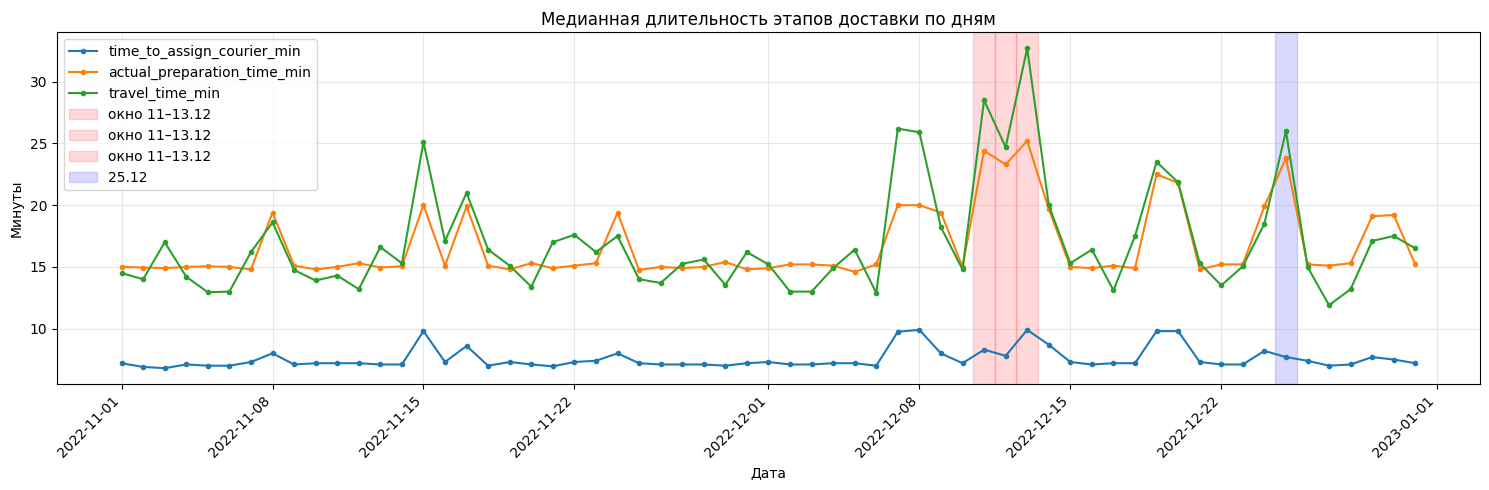

In [27]:
fig, ax = plt.subplots(figsize=(15, 5))
for col in stages:
    ax.plot(stage_med.index, stage_med[col], marker="o", ms=3, label=col)
ax.set_title("Медианная длительность этапов доставки по дням")
ax.set_ylabel("Минуты")
ax.set_xlabel("Дата")
highlight(ax, ANOM_A, "red",  "окно 11–13.12")
highlight(ax, ANOM_B, "blue", "25.12")
ax.legend(); ax.grid(alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

In [28]:
def day_profile(dates):
    idx = pd.to_datetime(dates)
    out = pd.DataFrame({
        "orders_total":     df.assign(d=pd.to_datetime(df["order_date"])).groupby("d").size().reindex(idx),
        "delivered":        deliv.groupby("order_date").size().reindex(idx),
        "cancel_user":      canc.get("Cancelled by user", pd.Series(0, index=canc.index)).reindex(idx),
        "cancel_no_courier":canc.get("No courier available", pd.Series(0, index=canc.index)).reindex(idx),
        "mean_assign":      stage_mean["time_to_assign_courier_min"].reindex(idx),
        "mean_prep":        stage_mean["actual_preparation_time_min"].reindex(idx),
        "mean_travel":      stage_mean["travel_time_min"].reindex(idx),
        "med_assign":       stage_med["time_to_assign_courier_min"].reindex(idx),
        "med_prep":         stage_med["actual_preparation_time_min"].reindex(idx),
        "med_travel":       stage_med["travel_time_min"].reindex(idx),
    })
    return out.round(2)

print("=== Окно A: 11–13.12 ===")
print(day_profile(["2022-12-11", "2022-12-12", "2022-12-13"]).to_string())
print("\n=== Окно B: 25.12 + соседние дни для сравнения ===")
print(day_profile(["2022-12-24", "2022-12-25", "2022-12-26"]).to_string())

=== Окно A: 11–13.12 ===
            orders_total  delivered  cancel_user  cancel_no_courier  mean_assign  mean_prep  mean_travel  med_assign  med_prep  med_travel
2022-12-11          1595       1276          109                210         9.91      22.88        29.66         8.3      24.4        28.5
2022-12-12           889        744           66                 79         9.40      22.06        26.54         7.8      23.3        24.7
2022-12-13          1069        820           48                201        11.40      23.90        33.54         9.9      25.2        32.7

=== Окно B: 25.12 + соседние дни для сравнения ===
            orders_total  delivered  cancel_user  cancel_no_courier  mean_assign  mean_prep  mean_travel  med_assign  med_prep  med_travel
2022-12-24          1649       1506          101                 42         8.76      19.02        19.90         8.2      19.9        18.5
2022-12-25          1527       1297          103                127         9.24      22.

#### 4. Поиск причин аномального поведения (шаг 2) — 3 балла
Постройте динамику метрик, в которых обнаружены аномалии, по базовым срезам (можете выбрать что-то одно: Completion Rate или Cancellation Rate, среднее время доставки или медиана времени доставки):
- платформа (iOS, Android);
- район адреса доставки;
- сегмент пользователя (новые / повторные);
- признак промо акции.

Выделяется ли какой-то сегмент, где аномалия выражена сильнее?

In [30]:
ANOM_A = pd.to_datetime(["2022-12-11", "2022-12-12", "2022-12-13"])
ANOM_B = pd.to_datetime(["2022-12-25"])

def agg_by(df, group_col):
    g = df.groupby(["order_date", group_col]).agg(
        total     = ("order_id", "count"),
        delivered = ("status", lambda s: (s == "delivered").sum()),
        avg_deliv = ("delivery_min", "mean"),
    ).reset_index()
    g["completion_rate"] = g["delivered"] / g["total"]
    return g

def highlight(ax):
    for d in ANOM_A:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12),
                   color="red", alpha=0.12, label="11–13.12" if d == ANOM_A[0] else None)
    for d in ANOM_B:
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12),
                   color="blue", alpha=0.12, label="25.12")

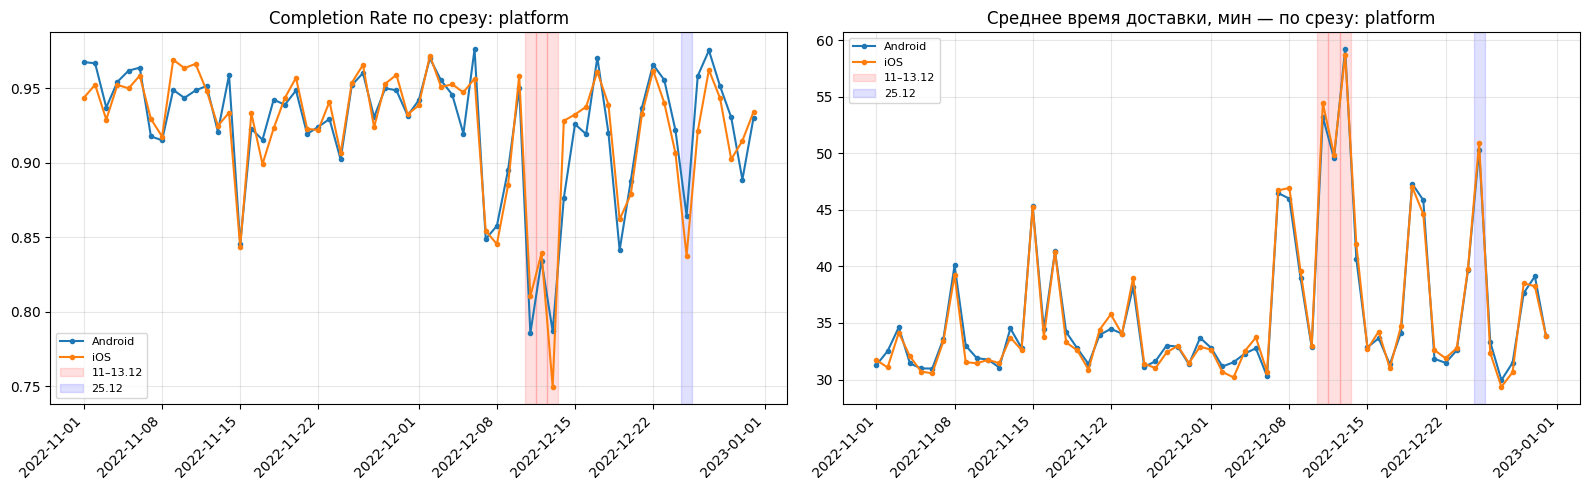

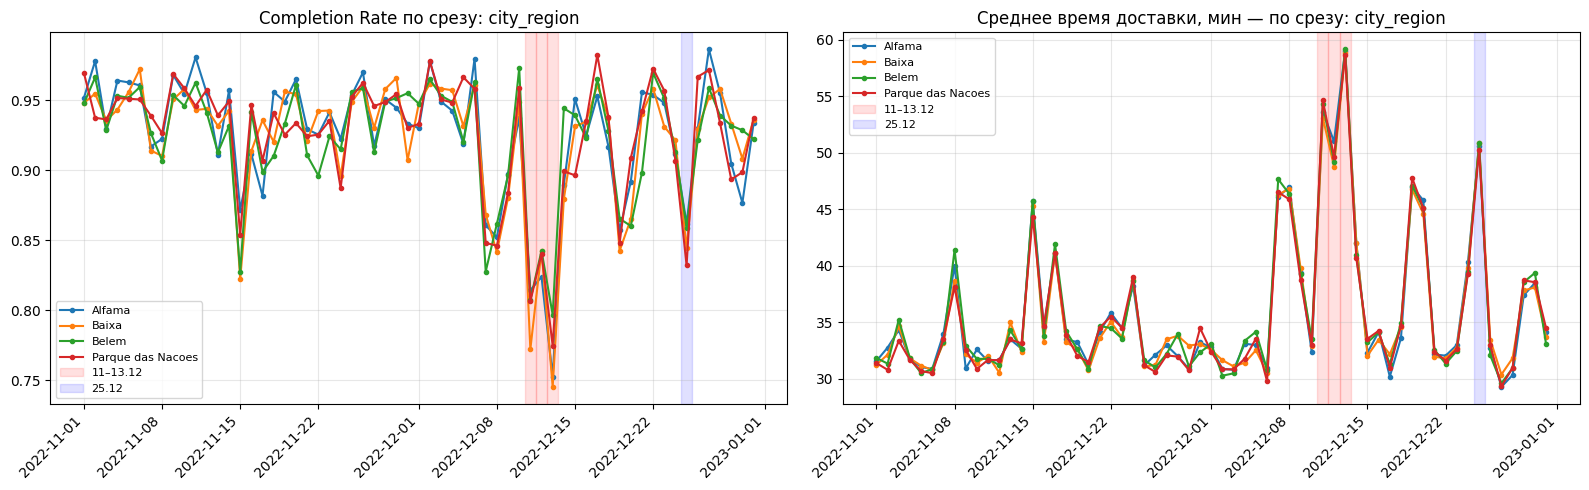

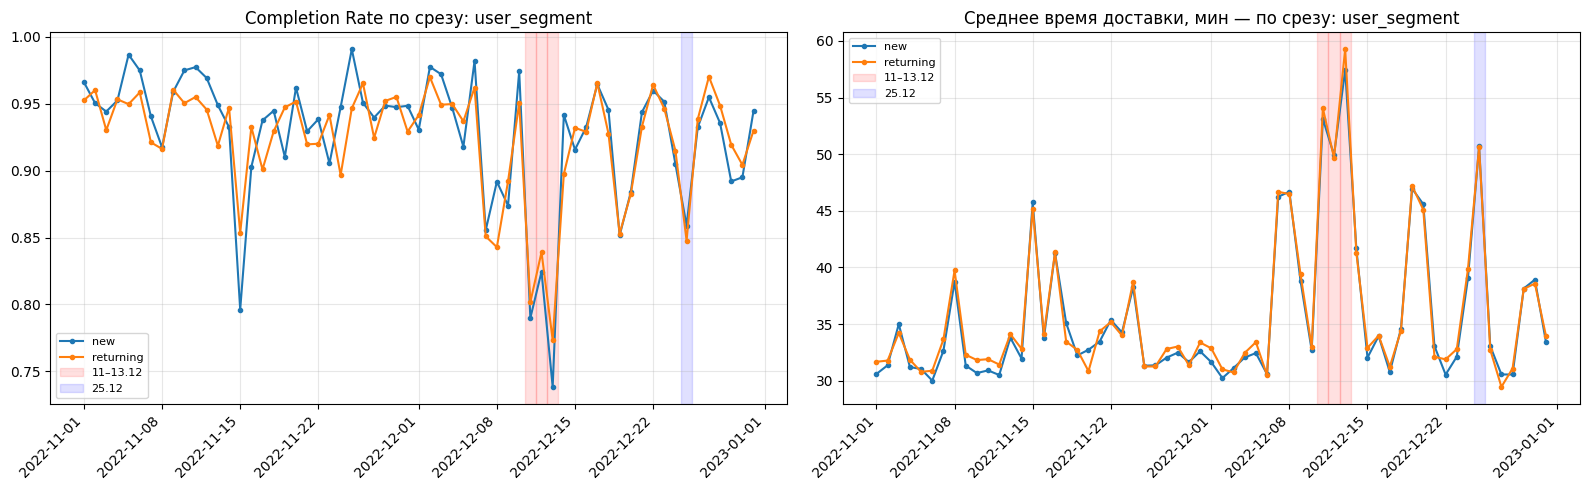

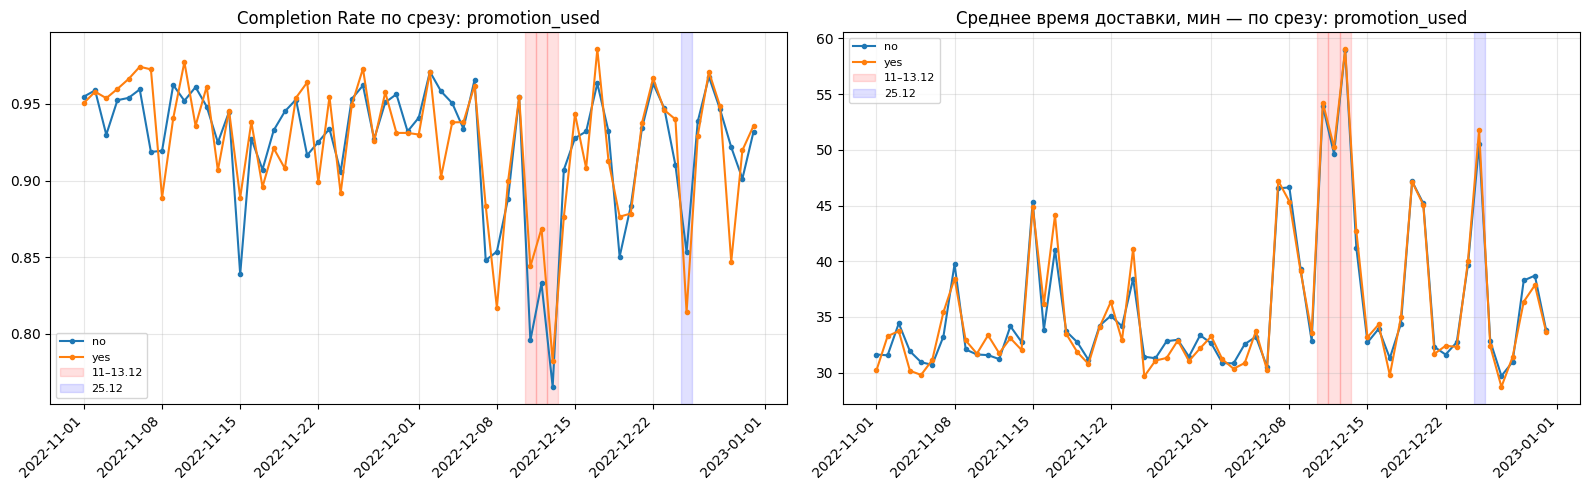

In [31]:
SLICES = {
    "platform":      "platform",
    "city_region":   "city_region",
    "user_segment":  "user_segment",
    "promotion_used":"promotion_used",
}

for slice_name, col in SLICES.items():
    g = agg_by(df, col)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharex=True)

    for key, sub in g.groupby(col):
        axes[0].plot(sub["order_date"], sub["completion_rate"], marker="o", ms=3, label=str(key))
        axes[1].plot(sub["order_date"], sub["avg_deliv"],       marker="o", ms=3, label=str(key))

    axes[0].set_title(f"Completion Rate по срезу: {slice_name}")
    axes[1].set_title(f"Среднее время доставки, мин — по срезу: {slice_name}")
    for ax in axes:
        highlight(ax)
        ax.grid(alpha=0.3)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

#### 5. Поиск причин аномального поведения (шаг 3) — 3 балла

Постройте динамику структуры заказов в разрезе сегментов:
- доля заказов по платформам;
- доля заказов по регионам города;
- доля заказов по сегменту пользователя;
- доля заказов по признаку промо акции.

Сравните даты аномалий с динамикой долей. Может ли изменение структуры объяснить падение метрик?

In [ ]:
# your code is here

#### 6. Поиск причин аномального поведения (шаг 4) — 3 балла
Разложение метрик на срезы не принесло результатов. Может быть причина аномалий лежит вне продукта?

Получите данные о погоде по API за весь анализируемый период по дням. Для этого используйте [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api?daily=temperature_2m_mean,wind_speed_10m_max,precipitation_sum) от Open-Meteo (регистрация и получение ключа не требуется, по ссылке есть пример запроса на Python).

- Для координат выгрузки возьмите: latitude: 38.736946, longitude: -9.142685;
- Timezone — auto;
- daily значения temperature_2m_mean, precipitation_sum, wind_speed_10m_max.

Соберите датасет с колонками: день, средняя температура воздуха, максимальная скорость ветра, суммарное количество осадков.

In [ ]:
# your code is here

#### 7. Поиск причин аномального поведения (шаг 5) — 3 балла
Объедините датасет метрик, в которых найдены аномалии, с датасетом погоды.    
Для каждой метрики постройте совместные визуализации данных погоды и продуктовой метрики.

Сформулируйте гипотезу — что могло повлиять на падение конверсии в дни аномалий? Как конверсия связана с другими метриками, для которых вы  обнаружили аномальные значения? Какую роль в изменении метрик могла сыграть погода?

In [ ]:
# your code is here

#### 8. Влияние на бизнес-результат — 3 балла
Примените один из методов декомпозиции из разобранных в первом семинаре, чтобы оценить вклад изменения конверсии и числа заказов в изменение числа доставок в декабре относительно ноября (MoM анализ).    

Постройте waterfall диаграмму.

Выпишите дни, которые внесли наибольший вклад в падение среднемесячной конверсии декабря относительно ноября. Пересекаются ли эти даты с датами повышенного числа осадков? Сделайте выводы.

In [ ]:
# your code is here

####  9. Анализ 24/7 — 3 балла

Одним из распространенных разрезов анализа метрик продуктов с внутринедельной сезонностью является разложение по дням недели и часам.

Постройте матрицу 24/7 (часы - дни недели) для ноября и декабря (в ячейку матрицы должно попасть агрегированное значение метрики для дня недели и часа), но перед этим очистите декабрьские значения от аномалий — для стабильной оценки нам нужны метрики без влияния экстремальной погоды.

Визуализацию стройте для:
- Числа заказов (всех);
- Completion Rate;
- Среднего или медианного времени доставки.

Подумайте, почему в определенные часы / дни недели мы наблюдаем падение конверсии? Как меняются остальные метрики?    
При ответе опирайтесь на статистические понятия — в какие-то часы просадка или, напротив, слишком высокая конверсия может быть не закономерностью, а случайностью из-за эффекта низкой базы в это время.

In [ ]:
# your code is here

####   10. Предложение по улучшению продукта — 3 балла
Базовым подходом для оптимизации работы в часы пик в доставке является динамическое ценообразование. В продукте эта механика еще не реализована. Вы смотрите на данные и решаете, что это отличная инициатива для планирования следующего квартала.

*Динамическое ценообразование помогает не только сглаживать часы повышенного спроса, но и регулировать работу продукта при внешних влияниях, когда пик спроса предсказать невозможно. В данном кейсе мы не рассматриваем такие решения, т.к. не стремимся написать алгоритм динамического прайсинга, а хотим провести базовое исследование проблем и поиск инициативы под быструю реализацию и тест. Поэтому в дальнейших заданиях речь идет исключительно о часах повышенного спроса, очищенных от аномалий.*

Чтобы протестировать гипотезу, достаточно простого подхода — увеличивать стоимость доставки на фиксированный процент (например, на 20%) в определенные дни недели-часы.

- На основе построенных в предыдущем задании матриц, предложите, в какие дни недели / часы вы порекомендуете увеличить стоимость доставки.
- Для каждого месяца рассчитайте долю заказов от общего числа, который будет иметь повышенную стоимость, согласно предложенным вами правилам повышения.

In [ ]:
# your code is here

### Часть 2. Дизайн эксперимента

Ваше предложение понравилось команде. Бэклог инициатив собран, время планировать роадмап. Вас просят провести дизайн эксперимента повышения стоимости доставки на 20% в регулярные часы повышенного спроса, чтобы команда поняла, сколько времени понадобится для получения результатов.

#### 1. Формат эксперимента — 3 балла

Выберите и обоснуйте единицу рандомизации теста:
- по-юзерный A/B тест,
- свитчбек по времени (например, 30-минутки);
- региональный A/B тест.

Вы отвечали на тестовый вопрос о такой же инициативе в ДЗ 3, возможно, это поможет определиться.

In [ ]:
# your answer is here

#### 2. Выбор таргет метрики — 3 балла

H1: Если мы введем динамическую наценку на доставку 20% в часы пик, то Completion Rate вырастет на 2%, а среднее время доставки снизится на 5%, потому что часть пользователей отложит заказ (снижение спроса), а повышенная оплата привлечет больше курьеров на линию (рост предложения).

Предложите таргет-метрику для эксперимента, обоснуйте свой выбор.

*Поскольку в гипотезе упоминаются сразу 2 метрики, и ни одна из них не является guardrail, метрику, которую вы не посчитаете таргетной, все равно будем учитывать в эксперименте как вторичную для принятия решения о результатах.*

In [ ]:
# your answer is here

#### 3. Выбор guardrails метрик — 3 балла

Выберите не более 3 guardrails-метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Guardrails метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

In [ ]:
# your answer is here

#### 4. Выбор информативных метрик — 3 балла

Выберите не более 3 информативных метрик для эксперимента из списка ниже, обоснуйте свой выбор.

- Доля отмен заказов;
- Доля отмен заказов по причине No courier available;
- Доля отмен заказов по причине Cancelled by user;
- Среднее время на поиск курьера time_to_assign_courier_min;
- Средняя стоимость доставки;
- Средний чек;
- Среднее gross revenue на заказ (average order value + delivery fee).

*Информативных метрик в тесте может быть больше, но нам важно понять логику ваших рассуждений при ограниченном выборе. Тут нет одного правильного ответа, будем учитывать проработку обоснования при оценке.*

In [ ]:
# your answer is here

#### 5. Поправка на множественное сравнение — 3 балла

Перед тем, как приступить к расчету длительности, выберите уровень значимости и мощность, которые будете использовать в расчетах далее. Отталкивайтесь от общепринятых alpha = 0.05 и beta = 0.2.

Для поправки на множественное сравнение можете взять поправку Бонферрони. Не забывайте, что мы корректируем alpha только на число метрик, непосредственно участвующих в принятии решения об успешности теста.

In [ ]:
# your answer is here

#### 6. Влияние выбросов на длительность эксперимента — 3 балла

В исследовательской части мы обнаружили аномальные значения метрик, вызванные внешними факторами. Такое состояние продукта не является целевым и случается достаточно редко.

На примере таргет метрики оцените дисперсию метрики, рассчитанную на значениях декабря полностью и с исключением аномального дня. Для исключения можете использовать **один** из подходов: удалить аномальный день или заменить его на другой не аномальный. Обоснуйте свой выбор.

Мы проводим эти расчеты в рамках дизайна эксперимента, поэтому в анализе используйте формулу (подсказки по формулам в задании ниже), которую будете применять для расчета длительности (ratio метрика, рассчитанная по единице рандомизации эксперимента).

Сделайте выводы о вариативности метрики при включении / исключении аномалии. Напишите, как разные подходы повлияют на длительность эксперимента и почему. Примите решение, какой из способов расчета будете применять вы в следующих шагах.

In [ ]:
# your code is here

#### 7. Длительность эксперимента — 3 балла

Рассчитайте длительность теста для выбранных таргет и вторичной метрик принятия решений.

Обратите внимание, что обе метрики — ratio, используйте подходы для работы с данным типом метрик.

---
**Формулы расчета объёма выборки через MDE для разных метрик**

**Для среднего**

$$
n \;=\; \frac{2\,\sigma^2 \,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$


**Для доли** (бинарная метрика)

$$
n \;\\=\;\; \frac{2\,p(1-p)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для Ratio-метрики дельта-методом**

$$
\mathrm{Var}\!\left(\tfrac{X}{Y}\right) \;\approx\;
\frac{1}{\mu_Y^2}\,\mathrm{Var}(X)
\;+\; \frac{\mu_X^2}{\mu_Y^4}\,\mathrm{Var}(Y)
\;-\; 2\,\frac{\mu_X}{\mu_Y^3}\,\mathrm{Cov}(X,Y)
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}\!\left(\tfrac{X}{Y}\right)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}
$$

**Для линеаризованной Ratio-метрики**   
Переходим для каждой единицы рандомизации к линеаризованной версии метрики:

$$
Z_i \;=\; \frac{\overline X}{\overline Y} \;+\; \frac{1}{\overline Y}\!\left( X_i \;-\; \frac{\overline X}{\overline Y}\, Y_i \right).
$$

тогда

$$
n \;=\; \frac{2 \cdot \mathrm{Var}(Z)\,\big(z_{1-\alpha/2}+z_{1-\beta}\big)^2}{\text{MDE}^2}.
$$


Для всех способов:
- Формулы указаны для групп одинакового размера (50/50) и двустороннего критерия;
- n — размер одной группы.

In [ ]:
# your code is here

#### 8. MDE для guardrails метрик — 3 балла

У нас нет информации по допустимым отрицательным эффектам для выбранных guardrails метрик, поступим обратным образом — рассчитайте минимальный детектируемый эффект для guardrails-метрик, используя максимальную длительность, полученную на предыдущем шаге (число дней целое и должно быть кратно 7 из-за недельной сезонности продукта).

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [ ]:
# your code is here

#### 9. MDE для информативных метрик — 3 балла

Рассчитайте MDE для выбранных информативных метрик также, как рассчитывали для guardrails.

Не забывайте, что в этом пункте вы тоже можете работать с ratio-метриками.

In [ ]:
# your code is here

#### 10. Правило принятия решения — 3 балла

Сформулируйте условия, при которых эксперимент считается успешным. Ваш ответ должен учитывать таргет-метрику, вторичную и guardrails.

Мы разбирали возможные варианты принятия решения об успешности в Лекции 3, можете использовать идеи оттуда.

In [ ]:
# your answer is here